In [ ]:
import pandas as pd
from google.colab import files
from io import BytesIO

uploaded = files.upload()

filename = next(iter(uploaded))
df = pd.read_csv(BytesIO(uploaded[filename]))

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("\nFirst 5 rows:")
display(df.head())

Saving Customer-Churn_data.csv to Customer-Churn_data.csv
Dataset loaded successfully!
Dataset shape: (7043, 21)

First 5 rows:


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [ ]:
# 1. Check column names and data types
print("DATASET INFORMATION")
df.info()

# 2. Check missing values in each column
print("\nMISSING VALUES")
print(df.isnull().sum())

# 3. Check duplicate records
print("\nDUPLICATE ROWS")
print("Total duplicates:", df.duplicated().sum())

# 4. Check the target column
print("\nCHURN DISTRIBUTION")
print(df["Churn"].value_counts())

# 5. Check the dataset size
print("\nDATASET SHAPE")
print(df.shape)

DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043

In [ ]:
# Inspect TotalCharges before cleaning
print("DATA TYPE:", df["TotalCharges"].dtype)

print("\nFIRST 20 VALUES:")
print(df["TotalCharges"].head(20).to_list())

print("\nBLANK OR WHITESPACE-ONLY VALUES:")
blank_mask = df["TotalCharges"].astype(str).str.strip().eq("")
print("Count:", blank_mask.sum())
display(df.loc[blank_mask, ["customerID", "tenure", "MonthlyCharges", "TotalCharges"]])

print("\nUNIQUE EXAMPLES:")
print(df["TotalCharges"].tail(10).to_list())

DATA TYPE: object

FIRST 20 VALUES:
['29.85', '1889.5', '108.15', '1840.75', '151.65', '820.5', '1949.4', '301.9', '3046.05', '3487.95', '587.45', '326.8', '5681.1', '5036.3', '2686.05', '7895.15', '1022.95', '7382.25', '528.35', '1862.9']

BLANK OR WHITESPACE-ONLY VALUES:
Count: 11


,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,
753,3115-CZMZD,0,20.25,
936,5709-LVOEQ,0,80.85,
1082,4367-NUYAO,0,25.75,
1340,1371-DWPAZ,0,56.05,
3331,7644-OMVMY,0,19.85,
3826,3213-VVOLG,0,25.35,
4380,2520-SGTTA,0,20.00,
5218,2923-ARZLG,0,19.70,
6670,4075-WKNIU,0,73.35,



UNIQUE EXAMPLES:
['2625.25', '6886.25', '1495.1', '743.3', '1419.4', '1990.5', '7362.9', '346.45', '306.6', '6844.5']


In [ ]:
# Create a backup before cleaning
df["TotalCharges_original"] = df["TotalCharges"]

# Remove surrounding whitespace and convert blanks to missing values
df["TotalCharges"] = df["TotalCharges"].astype(str).str.strip()
df["TotalCharges"] = df["TotalCharges"].replace("", pd.NA)

# Convert TotalCharges to a numeric column
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

# Verify the cleaning results
print("TotalCharges data type:", df["TotalCharges"].dtype)
print("Missing TotalCharges:", df["TotalCharges"].isna().sum())
print("Dataset shape:", df.shape)
print("\nAffected customer records:")
display(
    df.loc[
        df["TotalCharges"].isna(),
        ["customerID", "tenure", "MonthlyCharges", "TotalCharges"]
    ]
)

TotalCharges data type: float64
Missing TotalCharges: 11
Dataset shape: (7043, 22)

Affected customer records:


,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,NaN
753,3115-CZMZD,0,20.25,NaN
936,5709-LVOEQ,0,80.85,NaN
1082,4367-NUYAO,0,25.75,NaN
1340,1371-DWPAZ,0,56.05,NaN
3331,7644-OMVMY,0,19.85,NaN
3826,3213-VVOLG,0,25.35,NaN
4380,2520-SGTTA,0,20.00,NaN
5218,2923-ARZLG,0,19.70,NaN
6670,4075-WKNIU,0,73.35,NaN


In [ ]:
# 1. Verify data types
print("DATA TYPES")
print(df.dtypes)

# 2. Count missing values
print("\nMISSING VALUES")
print(df.isnull().sum()[df.isnull().sum() > 0])

# 3. Summary statistics for numeric columns
print("\nNUMERIC SUMMARY")
display(df[["tenure", "MonthlyCharges", "TotalCharges"]].describe())

# 4. Verify customer records
print("\nFINAL CHECK")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print("Duplicate rows:", df.duplicated().sum())

DATA TYPES
customerID                object
gender                    object
SeniorCitizen              int64
Partner                   object
Dependents                object
tenure                     int64
PhoneService              object
MultipleLines             object
InternetService           object
OnlineSecurity            object
OnlineBackup              object
DeviceProtection          object
TechSupport               object
StreamingTV               object
StreamingMovies           object
Contract                  object
PaperlessBilling          object
PaymentMethod             object
MonthlyCharges           float64
TotalCharges             float64
Churn                     object
TotalCharges_original     object
dtype: object

MISSING VALUES
TotalCharges    11
dtype: int64

NUMERIC SUMMARY


,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7032.000000
mean,32.371149,64.761692,2283.300441
std,24.559481,30.090047,2266.771362
min,0.000000,18.250000,18.800000
25%,9.000000,35.500000,401.450000
50%,29.000000,70.350000,1397.475000
75%,55.000000,89.850000,3794.737500
max,72.000000,118.750000,8684.800000



FINAL CHECK
Rows: 7043
Columns: 22
Duplicate rows: 0


In [ ]:
# Calculate overall customer churn
total_customers = len(df)

churn_counts = df["Churn"].value_counts()
churn_percentages = df["Churn"].value_counts(normalize=True) * 100

print("OVERALL CUSTOMER CHURN")
print("-" * 35)

print("Total customers:", total_customers)
print("Customers who stayed:", churn_counts["No"])
print("Customers who left:", churn_counts["Yes"])

print(f"\nRetention rate: {churn_percentages['No']:.2f}%")
print(f"Churn rate: {churn_percentages['Yes']:.2f}%")

OVERALL CUSTOMER CHURN
-----------------------------------
Total customers: 7043
Customers who stayed: 5174
Customers who left: 1869

Retention rate: 73.46%
Churn rate: 26.54%


CHURN RATE BY CONTRACT TYPE


Churn,No,Yes
Contract,,
Month-to-month,57.29,42.71
One year,88.73,11.27
Two year,97.17,2.83



CUSTOMER COUNTS BY CONTRACT TYPE


Churn,No,Yes
Contract,,
Month-to-month,2220,1655
One year,1307,166
Two year,1647,48


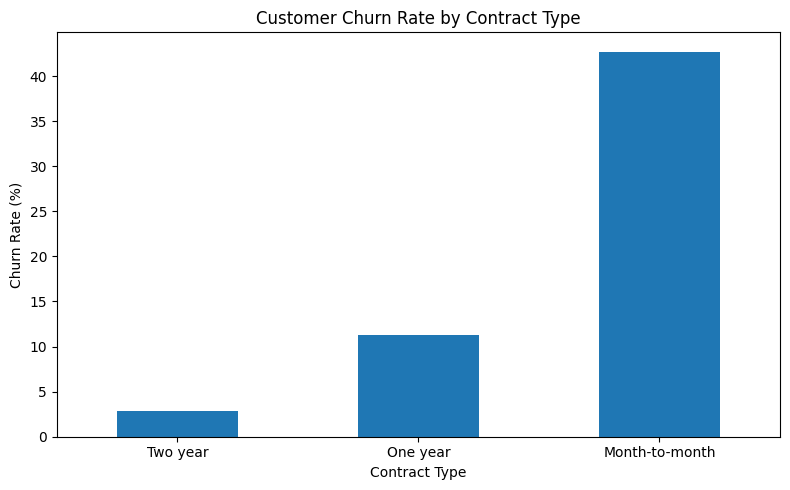

In [ ]:
# Calculate churn by contract type
contract_churn = pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
) * 100

print("CHURN RATE BY CONTRACT TYPE")
display(contract_churn.round(2))

# Calculate customer counts for each contract type
print("\nCUSTOMER COUNTS BY CONTRACT TYPE")
display(pd.crosstab(df["Contract"], df["Churn"]))

# Create a chart
import matplotlib.pyplot as plt

contract_churn["Yes"].sort_values().plot(
    kind="bar",
    figsize=(8, 5),
    title="Customer Churn Rate by Contract Type",
    ylabel="Churn Rate (%)",
    xlabel="Contract Type",
    rot=0
)

plt.tight_layout()
plt.show()

CHURN RATE BY TENURE GROUP


Churn,No,Yes
TenureGroup,,
0-12 months,52.56,47.44
13-24 months,71.29,28.71
25-48 months,79.61,20.39
49-72 months,90.49,9.51



CUSTOMER COUNTS BY TENURE GROUP


Churn,No,Yes
TenureGroup,,
0-12 months,1149,1037
13-24 months,730,294
25-48 months,1269,325
49-72 months,2026,213


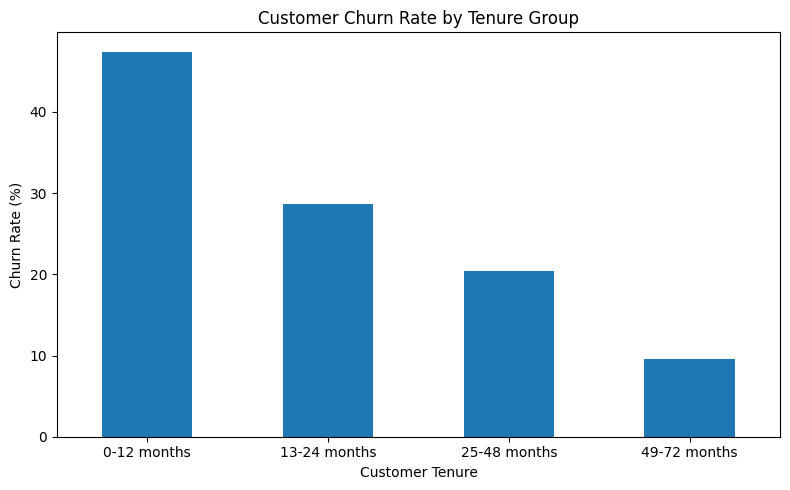

In [ ]:
# Create customer tenure groups
df["TenureGroup"] = pd.cut(
    df["tenure"],
    bins=[-1, 12, 24, 48, 72],
    labels=[
        "0-12 months",
        "13-24 months",
        "25-48 months",
        "49-72 months"
    ]
)

# Calculate churn rate within each tenure group
tenure_churn = pd.crosstab(
    df["TenureGroup"],
    df["Churn"],
    normalize="index"
) * 100

print("CHURN RATE BY TENURE GROUP")
display(tenure_churn.round(2))

# Customer counts in each tenure group
print("\nCUSTOMER COUNTS BY TENURE GROUP")
display(pd.crosstab(df["TenureGroup"], df["Churn"]))

# Visualize churn rate
import matplotlib.pyplot as plt

tenure_churn["Yes"].plot(
    kind="bar",
    figsize=(8, 5),
    title="Customer Churn Rate by Tenure Group",
    ylabel="Churn Rate (%)",
    xlabel="Customer Tenure",
    rot=0
)

plt.tight_layout()
plt.show()

CHURN RATE BY PAYMENT METHOD


Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),83.29,16.71
Credit card (automatic),84.76,15.24
Electronic check,54.71,45.29
Mailed check,80.89,19.11



CUSTOMER COUNTS BY PAYMENT METHOD


Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),1286,258
Credit card (automatic),1290,232
Electronic check,1294,1071
Mailed check,1304,308


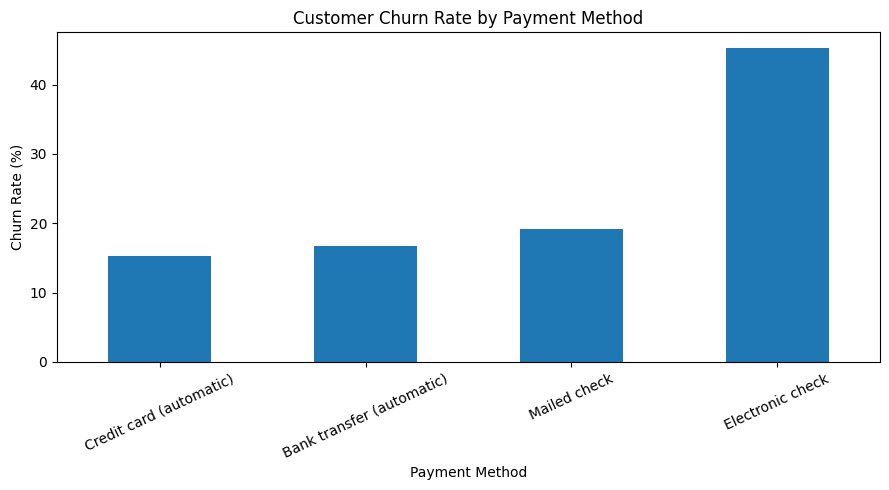

In [ ]:
# Calculate churn rate by payment method
payment_churn = pd.crosstab(
    df["PaymentMethod"],
    df["Churn"],
    normalize="index"
) * 100

print("CHURN RATE BY PAYMENT METHOD")
display(payment_churn.round(2))

print("\nCUSTOMER COUNTS BY PAYMENT METHOD")
display(pd.crosstab(df["PaymentMethod"], df["Churn"]))

# Visualize churn rate
import matplotlib.pyplot as plt

payment_churn["Yes"].sort_values().plot(
    kind="bar",
    figsize=(9, 5),
    title="Customer Churn Rate by Payment Method",
    ylabel="Churn Rate (%)",
    xlabel="Payment Method",
    rot=25
)

plt.tight_layout()
plt.show()

CHURN RATE BY INTERNET SERVICE


Churn,No,Yes
InternetService,,
DSL,81.04,18.96
Fiber optic,58.11,41.89
No,92.60,7.40



CUSTOMER COUNTS BY INTERNET SERVICE


Churn,No,Yes
InternetService,,
DSL,1962,459
Fiber optic,1799,1297
No,1413,113


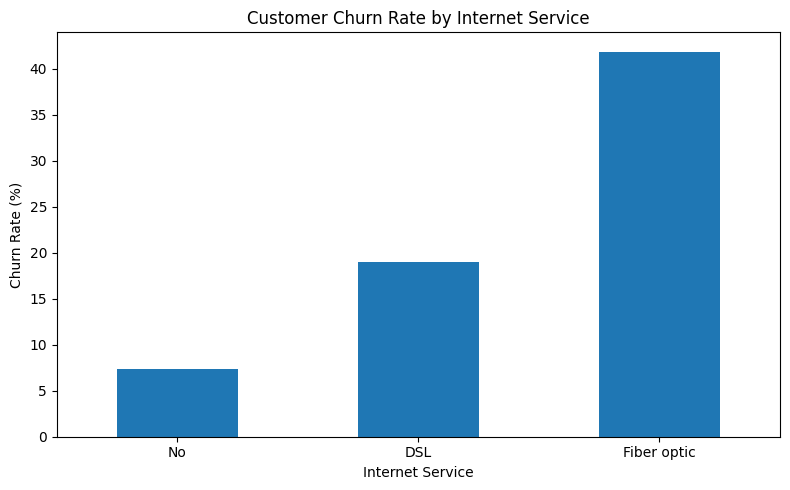

In [ ]:
# Calculate churn rate by internet service
internet_churn = pd.crosstab(
    df["InternetService"],
    df["Churn"],
    normalize="index"
) * 100

print("CHURN RATE BY INTERNET SERVICE")
display(internet_churn.round(2))

print("\nCUSTOMER COUNTS BY INTERNET SERVICE")
display(pd.crosstab(df["InternetService"], df["Churn"]))

# Visualize churn rate
import matplotlib.pyplot as plt

internet_churn["Yes"].sort_values().plot(
    kind="bar",
    figsize=(8, 5),
    title="Customer Churn Rate by Internet Service",
    ylabel="Churn Rate (%)",
    xlabel="Internet Service",
    rot=0
)

plt.tight_layout()
plt.show()

CHURN RATE BY MONTHLY CHARGES


Churn,No,Yes
MonthlyChargesGroup,,
Under $35,89.11,10.89
$35-$65,76.86,23.14
$65-$90,63.70,36.30
Above $90,67.22,32.78



CUSTOMER COUNTS BY MONTHLY CHARGES


Churn,No,Yes
MonthlyChargesGroup,,
Under $35,1546,189
$35-$65,1083,326
$65-$90,1376,784
Above $90,1169,570


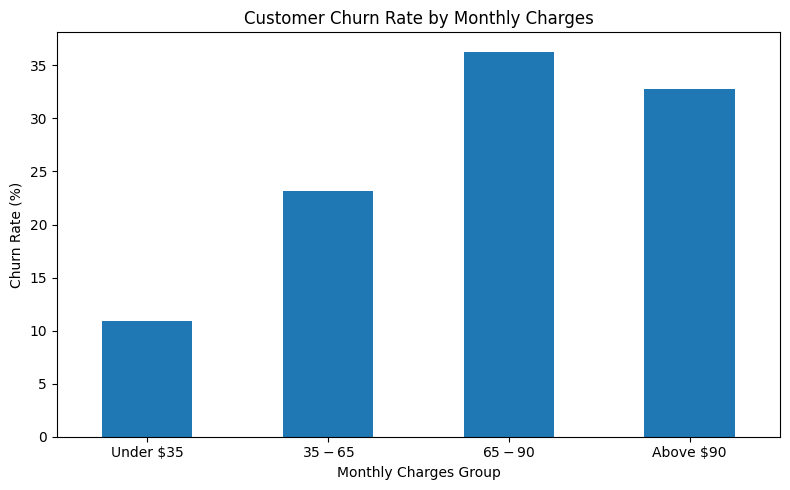

In [ ]:
# Create monthly charge groups
df["MonthlyChargesGroup"] = pd.cut(
    df["MonthlyCharges"],
    bins=[0, 35, 65, 90, float("inf")],
    labels=[
        "Under $35",
        "$35-$65",
        "$65-$90",
        "Above $90"
    ],
    include_lowest=True
)

# Calculate churn rates
charges_churn = pd.crosstab(
    df["MonthlyChargesGroup"],
    df["Churn"],
    normalize="index"
) * 100

print("CHURN RATE BY MONTHLY CHARGES")
display(charges_churn.round(2))

print("\nCUSTOMER COUNTS BY MONTHLY CHARGES")
display(pd.crosstab(df["MonthlyChargesGroup"], df["Churn"]))

# Plot churn rate
import matplotlib.pyplot as plt

charges_churn["Yes"].plot(
    kind="bar",
    figsize=(8, 5),
    title="Customer Churn Rate by Monthly Charges",
    ylabel="Churn Rate (%)",
    xlabel="Monthly Charges Group",
    rot=0
)

plt.tight_layout()
plt.show()

CHURN RATE BY ONLINE SECURITY


Churn,No,Yes
OnlineSecurity,,
No,58.23,41.77
No internet service,92.60,7.40
Yes,85.39,14.61



CUSTOMER COUNTS BY ONLINE SECURITY


Churn,No,Yes
OnlineSecurity,,
No,2037,1461
No internet service,1413,113
Yes,1724,295


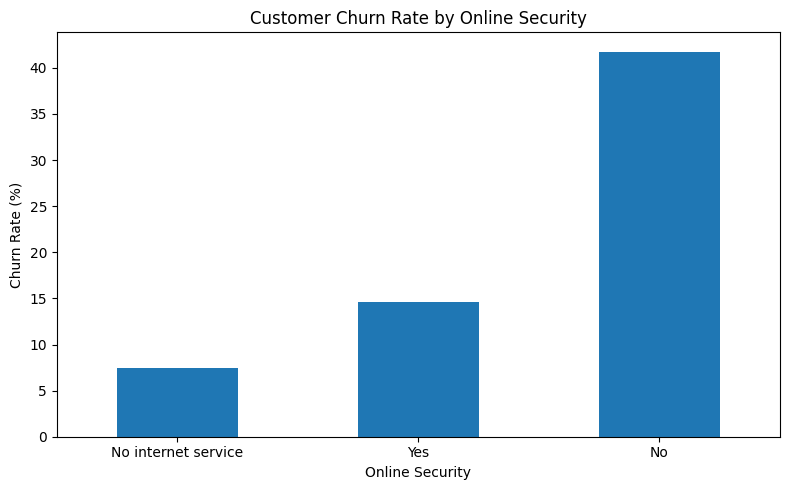

In [ ]:
# Calculate churn rate by online security
security_churn = pd.crosstab(
    df["OnlineSecurity"],
    df["Churn"],
    normalize="index"
) * 100

print("CHURN RATE BY ONLINE SECURITY")
display(security_churn.round(2))

print("\nCUSTOMER COUNTS BY ONLINE SECURITY")
display(pd.crosstab(df["OnlineSecurity"], df["Churn"]))

# Visualize churn rate
import matplotlib.pyplot as plt

security_churn["Yes"].sort_values().plot(
    kind="bar",
    figsize=(8, 5),
    title="Customer Churn Rate by Online Security",
    ylabel="Churn Rate (%)",
    xlabel="Online Security",
    rot=0
)

plt.tight_layout()
plt.show()

CHURN RATE BY TECH SUPPORT


Churn,No,Yes
TechSupport,,
No,58.36,41.64
No internet service,92.60,7.40
Yes,84.83,15.17



CUSTOMER COUNTS BY TECH SUPPORT


Churn,No,Yes
TechSupport,,
No,2027,1446
No internet service,1413,113
Yes,1734,310


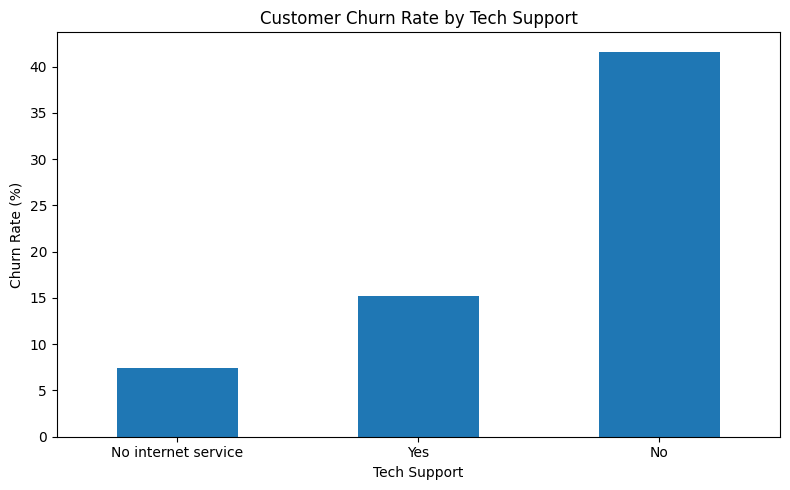

In [ ]:
# Calculate churn rate by tech support
support_churn = pd.crosstab(
    df["TechSupport"],
    df["Churn"],
    normalize="index"
) * 100

print("CHURN RATE BY TECH SUPPORT")
display(support_churn.round(2))

print("\nCUSTOMER COUNTS BY TECH SUPPORT")
display(pd.crosstab(df["TechSupport"], df["Churn"]))

# Visualize churn rate
import matplotlib.pyplot as plt

support_churn["Yes"].sort_values().plot(
    kind="bar",
    figsize=(8, 5),
    title="Customer Churn Rate by Tech Support",
    ylabel="Churn Rate (%)",
    xlabel="Tech Support",
    rot=0
)

plt.tight_layout()
plt.show()

CHURN RATE BY TENURE AND CONTRACT TYPE (%)


Contract,Month-to-month,One year,Two year
TenureGroup,,,
0-12 months,51.35,10.48,0.00
13-24 months,37.72,8.12,0.00
25-48 months,32.92,10.62,2.19
49-72 months,26.02,12.93,3.33


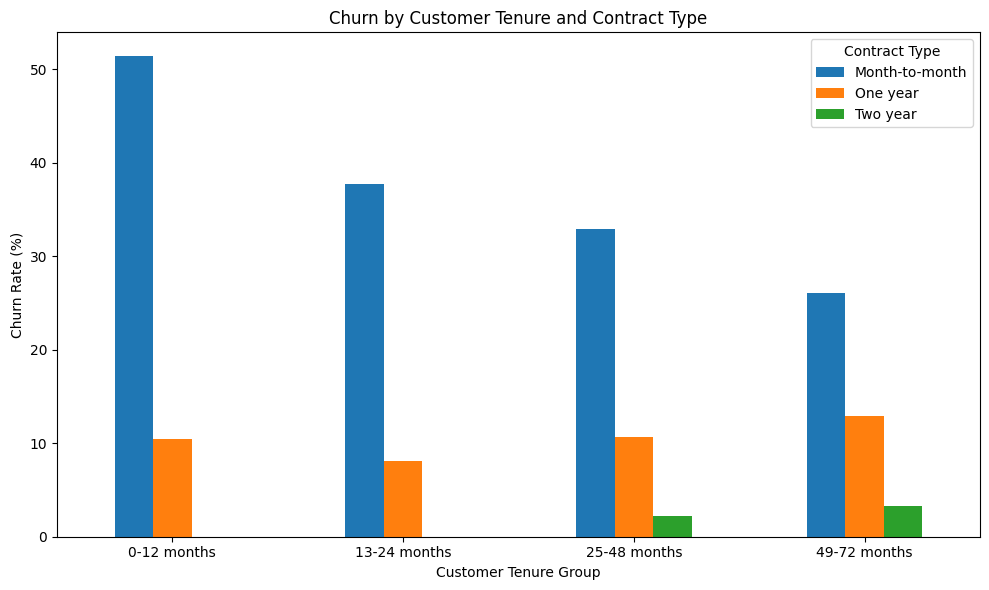

In [ ]:
# Compare churn across contract type and tenure group
contract_tenure_churn = pd.pivot_table(
    df,
    index="TenureGroup",
    columns="Contract",
    values="Churn",
    aggfunc=lambda x: (x == "Yes").mean() * 100,
    observed=False
)

print("CHURN RATE BY TENURE AND CONTRACT TYPE (%)")
display(contract_tenure_churn.round(2))

# Visualize the comparison
import matplotlib.pyplot as plt

contract_tenure_churn.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Churn by Customer Tenure and Contract Type")
plt.xlabel("Customer Tenure Group")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.legend(title="Contract Type")
plt.tight_layout()
plt.show()

CHURN RATE BY MONTHLY CHARGES AND CONTRACT (%)


Contract,Month-to-month,One year,Two year
MonthlyChargesGroup,,,
Under $35,24.29,3.12,0.78
$35-$65,33.94,7.67,2.26
$65-$90,51.50,11.25,1.78
Above $90,52.16,20.85,7.08


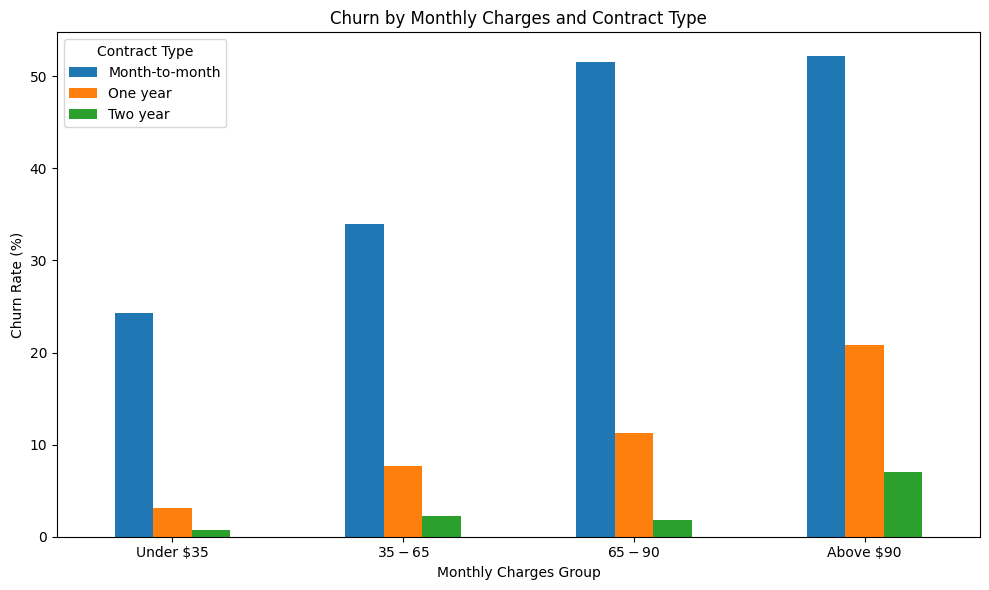

In [ ]:
# Churn rate by contract type and monthly charge group
charges_contract_churn = pd.pivot_table(
    df,
    index="MonthlyChargesGroup",
    columns="Contract",
    values="Churn",
    aggfunc=lambda x: (x == "Yes").mean() * 100,
    observed=False
)

print("CHURN RATE BY MONTHLY CHARGES AND CONTRACT (%)")
display(charges_contract_churn.round(2))

# Visualize
charges_contract_churn.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Churn by Monthly Charges and Contract Type")
plt.xlabel("Monthly Charges Group")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.legend(title="Contract Type")
plt.tight_layout()
plt.show()


CHURN RATE BY GENDER


Churn,No,Yes
gender,,
Female,73.08,26.92
Male,73.84,26.16


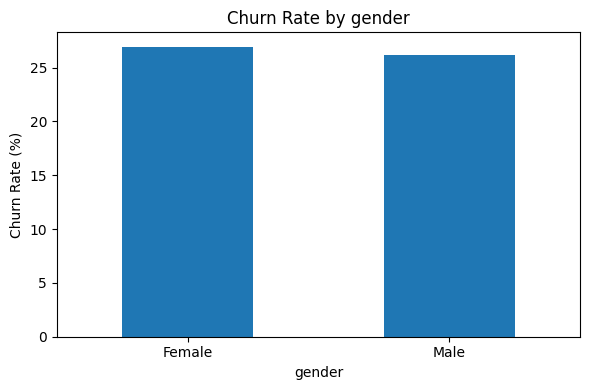


CHURN RATE BY SENIORCITIZEN


Churn,No,Yes
SeniorCitizen,,
0,76.39,23.61
1,58.32,41.68


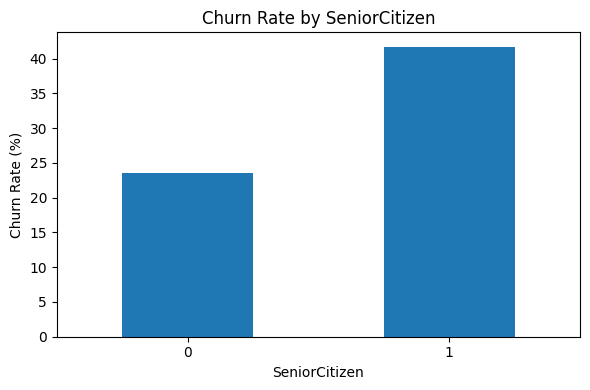


CHURN RATE BY PARTNER


Churn,No,Yes
Partner,,
No,67.04,32.96
Yes,80.34,19.66


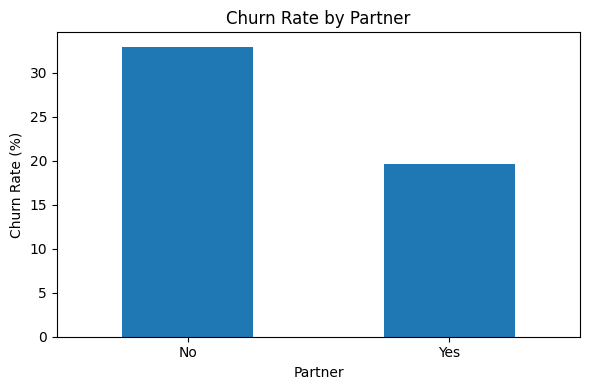


CHURN RATE BY DEPENDENTS


Churn,No,Yes
Dependents,,
No,68.72,31.28
Yes,84.55,15.45


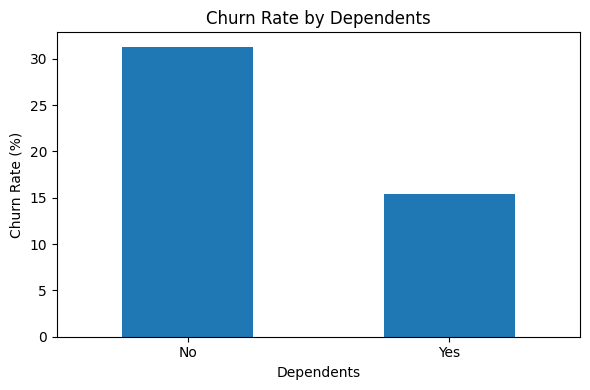

In [ ]:
# Step 17: Churn by customer demographics

demographic_columns = [
    "gender",
    "SeniorCitizen",
    "Partner",
    "Dependents"
]

for col in demographic_columns:
    print(f"\nCHURN RATE BY {col.upper()}")

    churn_rate = pd.crosstab(
        df[col],
        df["Churn"],
        normalize="index"
    ) * 100

    display(churn_rate.round(2))

    # Plot churn percentage only
    churn_rate["Yes"].plot(
        kind="bar",
        figsize=(6, 4),
        title=f"Churn Rate by {col}",
        ylabel="Churn Rate (%)",
        xlabel=col,
        rot=0
    )

    plt.tight_layout()
    plt.show()

In [ ]:

# STEP 1: Audit remaining categorical features

features_to_check = [
    "Partner",
    "Dependents",
    "SeniorCitizen",
    "PhoneService",
    "MultipleLines",
    "OnlineBackup",
    "DeviceProtection",
    "StreamingTV",
    "StreamingMovies",
    "PaperlessBilling"
]

# Only analyze columns that exist in the dataset
features_to_check = [
    col for col in features_to_check
    if col in df.columns
]

for col in features_to_check:
    print(f"\n{'=' * 55}")
    print(f"CHURN ANALYSIS: {col}")
    print("=" * 55)

    # Customer counts by feature value and churn status
    counts = pd.crosstab(df[col], df["Churn"])

    # Churn percentage within each feature group
    churn_rate = (
        pd.crosstab(df[col], df["Churn"], normalize="index")
        .mul(100)
        .round(2)
    )

    print("\nCUSTOMER COUNTS:")
    print(counts)

    print("\nCHURN RATE BY GROUP (%):")
    if "Yes" in churn_rate.columns:
        print(churn_rate[["Yes"]].rename(
            columns={"Yes": "Churn Rate (%)"}
        ))
    else:
        print("No 'Yes' category found in Churn.")



CHURN ANALYSIS: Partner

CUSTOMER COUNTS:
Churn      No   Yes
Partner            
No       2441  1200
Yes      2733   669

CHURN RATE BY GROUP (%):
Churn    Churn Rate (%)
Partner                
No                32.96
Yes               19.66

CHURN ANALYSIS: Dependents

CUSTOMER COUNTS:
Churn         No   Yes
Dependents            
No          3390  1543
Yes         1784   326

CHURN RATE BY GROUP (%):
Churn       Churn Rate (%)
Dependents                
No                   31.28
Yes                  15.45

CHURN ANALYSIS: SeniorCitizen

CUSTOMER COUNTS:
Churn            No   Yes
SeniorCitizen            
0              4508  1393
1               666   476

CHURN RATE BY GROUP (%):
Churn          Churn Rate (%)
SeniorCitizen                
0                       23.61
1                       41.68

CHURN ANALYSIS: PhoneService

CUSTOMER COUNTS:
Churn           No   Yes
PhoneService            
No             512   170
Yes           4662  1699

CHURN RATE BY GROUP (%):
Churn     

In [18]:

# STEP 2: Numerical analysis by churn status

numeric_cols = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

print("CUSTOMER COUNTS BY CHURN STATUS")
print(df["Churn"].value_counts())

print("\nAVERAGE VALUES BY CHURN STATUS")
print(
    df.groupby("Churn")[numeric_cols]
      .mean()
      .round(2)
)

print("\nMEDIAN VALUES BY CHURN STATUS")
print(
    df.groupby("Churn")[numeric_cols]
      .median()
      .round(2)
)

print("\nCUSTOMER TENURE AND CHARGES SUMMARY")
print(
    df.groupby("Churn")[numeric_cols]
      .agg(["mean", "median", "min", "max"])
      .round(2)
)


CUSTOMER COUNTS BY CHURN STATUS
Churn
No     5174
Yes    1869
Name: count, dtype: int64

AVERAGE VALUES BY CHURN STATUS
       tenure  MonthlyCharges  TotalCharges
Churn                                      
No      37.57           61.27       2555.34
Yes     17.98           74.44       1531.80

MEDIAN VALUES BY CHURN STATUS
       tenure  MonthlyCharges  TotalCharges
Churn                                      
No       38.0           64.43       1683.60
Yes      10.0           79.65        703.55

CUSTOMER TENURE AND CHARGES SUMMARY
      tenure                MonthlyCharges                       TotalCharges  \
        mean median min max           mean median    min     max         mean   
Churn                                                                           
No     37.57   38.0   0  72          61.27  64.43  18.25  118.75      2555.34   
Yes    17.98   10.0   1  72          74.44  79.65  18.85  118.35      1531.80   

                                
        median    min

CORRELATION MATRIX


,tenure,MonthlyCharges,TotalCharges,ChurnNumeric
tenure,1.000,0.248,0.826,-0.352
MonthlyCharges,0.248,1.000,0.651,0.193
TotalCharges,0.826,0.651,1.000,-0.199
ChurnNumeric,-0.352,0.193,-0.199,1.000



CORRELATION WITH CHURN


,Correlation with churn
tenure,-0.352
TotalCharges,-0.199
MonthlyCharges,0.193


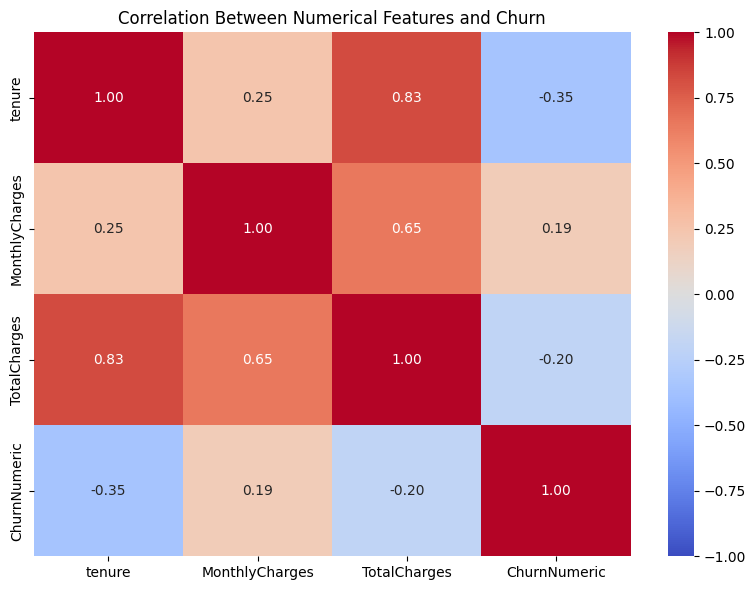

In [19]:

import matplotlib.pyplot as plt
import seaborn as sns

# Create a numeric churn indicator for correlation analysis
correlation_df = df[
    ["tenure", "MonthlyCharges", "TotalCharges", "Churn"]
].copy()

correlation_df["ChurnNumeric"] = (
    correlation_df["Churn"].map({"No": 0, "Yes": 1})
)

# Calculate correlations
corr = correlation_df[
    ["tenure", "MonthlyCharges", "TotalCharges", "ChurnNumeric"]
].corr()

print("CORRELATION MATRIX")
display(corr.round(3))

print("\nCORRELATION WITH CHURN")
display(
    corr["ChurnNumeric"]
    .drop("ChurnNumeric")
    .sort_values()
    .to_frame("Correlation with churn")
    .round(3)
)

# Visualize the relationships
plt.figure(figsize=(8, 6))
sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    fmt=".2f"
)
plt.title("Correlation Between Numerical Features and Churn")
plt.tight_layout()
plt.show()


In [20]:
# DATA QUALITY AUDIT

print("=" * 50)
print("1. DATASET DIMENSIONS")
print("=" * 50)
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\n" + "=" * 50)
print("2. COLUMN DATA TYPES")
print("=" * 50)
df.info()

print("\n" + "=" * 50)
print("3. MISSING VALUES")
print("=" * 50)
print(df.isnull().sum().sort_values(ascending=False))

print("\n" + "=" * 50)
print("4. DUPLICATE ROWS")
print("=" * 50)
print("Duplicate rows:", df.duplicated().sum())

print("\n" + "=" * 50)
print("5. BLANK TEXT VALUES")
print("=" * 50)
print(
    df.select_dtypes(include="object")
      .apply(lambda col: col.astype("string").str.strip().eq("").sum())
      .sort_values(ascending=False)
)

print("\n" + "=" * 50)
print("6. TOTAL CHARGES CHECK")
print("=" * 50)
if "TotalCharges" in df.columns:
    print("Data type:", df["TotalCharges"].dtype)
    print(
        "Blank TotalCharges:",
        df["TotalCharges"].astype("string").str.strip().eq("").sum()
    )
    print("Missing TotalCharges:", df["TotalCharges"].isnull().sum())

1. DATASET DIMENSIONS
Rows: 7043
Columns: 24

2. COLUMN DATA TYPES
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 24 columns):
 #   Column                 Non-Null Count  Dtype   
---  ------                 --------------  -----   
 0   customerID             7043 non-null   object  
 1   gender                 7043 non-null   object  
 2   SeniorCitizen          7043 non-null   int64   
 3   Partner                7043 non-null   object  
 4   Dependents             7043 non-null   object  
 5   tenure                 7043 non-null   int64   
 6   PhoneService           7043 non-null   object  
 7   MultipleLines          7043 non-null   object  
 8   InternetService        7043 non-null   object  
 9   OnlineSecurity         7043 non-null   object  
 10  OnlineBackup           7043 non-null   object  
 11  DeviceProtection       7043 non-null   object  
 12  TechSupport            7043 non-null   object  
 13  StreamingTV            704

In [21]:
# INVESTIGATE MISSING TOTAL CHARGES

missing_total = df[df["TotalCharges"].isna()]

print("Number of customers with missing TotalCharges:",
      len(missing_total))

print("\nTenure values for these customers:")
print(missing_total["tenure"].value_counts(dropna=False))

print("\nDetails of affected customers:")
display(
    missing_total[
        [
            "customerID",
            "tenure",
            "MonthlyCharges",
            "TotalCharges_original",
            "Churn",
            "Contract"
        ]
    ]
)

Number of customers with missing TotalCharges: 11

Tenure values for these customers:
tenure
0    11
Name: count, dtype: int64

Details of affected customers:


,customerID,tenure,MonthlyCharges,TotalCharges_original,Churn,Contract
488,4472-LVYGI,0,52.55,,No,Two year
753,3115-CZMZD,0,20.25,,No,Two year
936,5709-LVOEQ,0,80.85,,No,Two year
1082,4367-NUYAO,0,25.75,,No,Two year
1340,1371-DWPAZ,0,56.05,,No,Two year
3331,7644-OMVMY,0,19.85,,No,Two year
3826,3213-VVOLG,0,25.35,,No,Two year
4380,2520-SGTTA,0,20.00,,No,Two year
5218,2923-ARZLG,0,19.70,,No,One year
6670,4075-WKNIU,0,73.35,,No,Two year


In [22]:
# VERIFY THE CLEANING DECISION

print("Missing TotalCharges before cleaning:",
      df["TotalCharges"].isna().sum())

print("Missing TotalCharges among zero-tenure customers:",
      df.loc[df["tenure"].eq(0), "TotalCharges"].isna().sum())

print("Zero-tenure customers:",
      df["tenure"].eq(0).sum())

Missing TotalCharges before cleaning: 11
Missing TotalCharges among zero-tenure customers: 11
Zero-tenure customers: 11


In [23]:
# CLEAN MISSING TOTAL CHARGES

# Record the number of missing values before cleaning
missing_before = df["TotalCharges"].isna().sum()

# Fill missing TotalCharges for zero-tenure customers
df.loc[
    df["tenure"].eq(0) & df["TotalCharges"].isna(),
    "TotalCharges"
] = 0

# Verify the result
print("Missing values before cleaning:", missing_before)
print("Missing TotalCharges after cleaning:",
      df["TotalCharges"].isna().sum())
print("Total customer records:", len(df))
print("Zero-tenure customers:", df["tenure"].eq(0).sum())

# Confirm the original column remains unchanged
print("Blank values preserved in TotalCharges_original:",
      df["TotalCharges_original"].astype("string").str.strip().eq("").sum())

Missing values before cleaning: 11
Missing TotalCharges after cleaning: 0
Total customer records: 7043
Zero-tenure customers: 11
Blank values preserved in TotalCharges_original: 11


In [24]:
# OVERALL CUSTOMER CHURN ANALYSIS

total_customers = len(df)
churn_counts = df["Churn"].value_counts()
churn_percentages = df["Churn"].value_counts(normalize=True) * 100

print("=" * 45)
print("OVERALL CUSTOMER CHURN SUMMARY")
print("=" * 45)

print("Total customers:", total_customers)

print("\nCustomer counts by churn status:")
print(churn_counts)

print("\nCustomer percentages by churn status:")
print(churn_percentages.round(2))

churn_rate = (df["Churn"].eq("Yes").sum() / total_customers) * 100

print(f"\nOverall churn rate: {churn_rate:.2f}%")
print(f"Overall retention rate: {100 - churn_rate:.2f}%")

OVERALL CUSTOMER CHURN SUMMARY
Total customers: 7043

Customer counts by churn status:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Customer percentages by churn status:
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64

Overall churn rate: 26.54%
Overall retention rate: 73.46%


In [25]:
# STEP 5: CATEGORICAL EDA COMPLETENESS AUDIT

categorical_columns = df.select_dtypes(
    include=["object", "category"]
).columns.tolist()

completed_analyses = [
    "Contract",
    "PaymentMethod",
    "InternetService",
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies",
    "gender",
    "SeniorCitizen",
    "Partner",
    "Dependents",
    "PhoneService",
    "MultipleLines",
    "PaperlessBilling"
]

print("CATEGORICAL COLUMNS IN DATASET:")
print(categorical_columns)

print("\nFEATURES ALREADY ANALYZED:")
print(completed_analyses)

remaining = [
    col for col in categorical_columns
    if col not in completed_analyses
    and col not in ["customerID", "TotalCharges_original", "Churn"]
]

print("\nFEATURES NOT YET ANALYZED:")
print(remaining)

CATEGORICAL COLUMNS IN DATASET:
['customerID', 'gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'Churn', 'TotalCharges_original', 'TenureGroup', 'MonthlyChargesGroup']

FEATURES ALREADY ANALYZED:
['Contract', 'PaymentMethod', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'PaperlessBilling']

FEATURES NOT YET ANALYZED:
['TenureGroup', 'MonthlyChargesGroup']


In [26]:
print("FINAL DATA QUALITY CHECK")
print("-" * 40)

print("Dataset shape:", df.shape)

print("\nMissing values in important columns:")
print(df[[
    "tenure",
    "MonthlyCharges",
    "TotalCharges",
    "Churn"
]].isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nChurn target distribution:")
print(df["Churn"].value_counts())

print("\nChurn target percentages:")
print(
    (df["Churn"].value_counts(normalize=True) * 100)
    .round(2)
    .astype(str) + "%"
)

print("\nData types:")
print(df[[
    "tenure",
    "MonthlyCharges",
    "TotalCharges",
    "Churn"
]].dtypes)

FINAL DATA QUALITY CHECK
----------------------------------------
Dataset shape: (7043, 24)

Missing values in important columns:
tenure            0
MonthlyCharges    0
TotalCharges      0
Churn             0
dtype: int64

Duplicate rows: 0

Churn target distribution:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn target percentages:
Churn
No     73.46%
Yes    26.54%
Name: proportion, dtype: object

Data types:
tenure              int64
MonthlyCharges    float64
TotalCharges      float64
Churn              object
dtype: object


In [27]:
df["ChurnNumeric"] = df["Churn"].map({
    "No": 0,
    "Yes": 1
})

print("Original Churn values:")
print(df["Churn"].value_counts())

print("\nEncoded Churn values:")
print(df["ChurnNumeric"].value_counts())

print("\nCheck for missing encoded values:")
print(df["ChurnNumeric"].isnull().sum())

print("\nFinal dataset shape:", df.shape)

Original Churn values:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Encoded Churn values:
ChurnNumeric
0    5174
1    1869
Name: count, dtype: int64

Check for missing encoded values:
0

Final dataset shape: (7043, 25)


In [28]:
# Separate input features (X) and target (y)

X = df.drop(columns=[
    "Churn",
    "ChurnNumeric",
    "customerID",
    "TotalCharges_original"
])

y = df["ChurnNumeric"]

print("Features (X) shape:", X.shape)
print("Target (y) shape:", y.shape)

print("\nFeature columns:")
print(X.columns.tolist())

print("\nTarget distribution:")
print(y.value_counts())

Features (X) shape: (7043, 21)
Target (y) shape: (7043,)

Feature columns:
['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'TenureGroup', 'MonthlyChargesGroup']

Target distribution:
ChurnNumeric
0    5174
1    1869
Name: count, dtype: int64


In [29]:
X = X.drop(columns=[
    "TenureGroup",
    "MonthlyChargesGroup"
])

print("Updated X shape:", X.shape)
print("\nFeature columns:")
print(X.columns.tolist())

Updated X shape: (7043, 19)

Feature columns:
['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges']


In [30]:
# Identify numerical and categorical features

numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Numerical features:", len(numerical_features))
print(numerical_features)

print("\nCategorical features:", len(categorical_features))
print(categorical_features)

print("\nData types of all features:")
print(X.dtypes)

Numerical features: 4
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical features: 15
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Data types of all features:
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges        float64
dtype: object


In [31]:
# Define feature groups for preprocessing

numerical_features = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

categorical_features = [
    "gender",
    "SeniorCitizen",
    "Partner",
    "Dependents",
    "PhoneService",
    "MultipleLines",
    "InternetService",
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies",
    "Contract",
    "PaperlessBilling",
    "PaymentMethod"
]

print("Numerical features:", len(numerical_features))
print(numerical_features)

print("\nCategorical features:", len(categorical_features))
print(categorical_features)

print("\nTotal features:", len(numerical_features) + len(categorical_features))
print("Features in X:", X.shape[1])

Numerical features: 3
['tenure', 'MonthlyCharges', 'TotalCharges']

Categorical features: 16
['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Total features: 19
Features in X: 19


In [32]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target:", y_train.shape)
print("Testing target:", y_test.shape)

print("\nTraining churn percentages:")
print((y_train.value_counts(normalize=True) * 100).round(2))

print("\nTesting churn percentages:")
print((y_test.value_counts(normalize=True) * 100).round(2))

Training features: (5634, 19)
Testing features: (1409, 19)

Training target: (5634,)
Testing target: (1409,)

Training churn percentages:
ChurnNumeric
0    73.46
1    26.54
Name: proportion, dtype: float64

Testing churn percentages:
ChurnNumeric
0    73.46
1    26.54
Name: proportion, dtype: float64


In [33]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Preprocessing for numerical features
numerical_transformer = StandardScaler()

# Preprocessing for categorical features
categorical_transformer = OneHotEncoder(
    handle_unknown="ignore"
)

# Combine both preprocessing steps
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessor created successfully.")
print("\nNumerical features:", numerical_features)
print("\nCategorical features:", categorical_features)

Preprocessor created successfully.

Numerical features: ['tenure', 'MonthlyCharges', 'TotalCharges']

Categorical features: ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


In [34]:
# Fit preprocessing on training data only
X_train_processed = preprocessor.fit_transform(X_train)

# Apply the learned preprocessing to test data
X_test_processed = preprocessor.transform(X_test)

print("Training data before preprocessing:", X_train.shape)
print("Training data after preprocessing:", X_train_processed.shape)

print("\nTesting data before preprocessing:", X_test.shape)
print("Testing data after preprocessing:", X_test_processed.shape)

print("\nTraining data contains missing values:",
      pd.isna(X_train_processed).sum())

print("Testing data contains missing values:",
      pd.isna(X_test_processed).sum())

Training data before preprocessing: (5634, 19)
Training data after preprocessing: (5634, 46)

Testing data before preprocessing: (1409, 19)
Testing data after preprocessing: (1409, 46)

Training data contains missing values: 0
Testing data contains missing values: 0


In [35]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

# Create the model
logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train using the processed training data
logistic_model.fit(X_train_processed, y_train)

# Predict churn on unseen test data
y_pred = logistic_model.predict(X_test_processed)

# Evaluate the model
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Stayed (0)", "Churned (1)"]
))

Accuracy: 0.8055

Classification Report:
              precision    recall  f1-score   support

  Stayed (0)       0.85      0.89      0.87      1035
 Churned (1)       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



Confusion Matrix:
[[926 109]
 [165 209]]


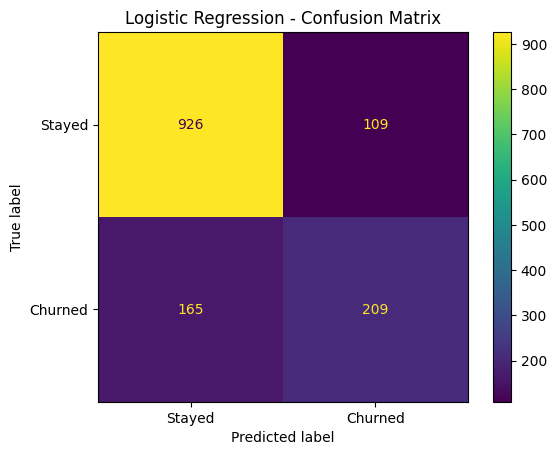

In [36]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Calculate confusion matrix
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

# Display the matrix
display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Stayed", "Churned"]
)

display.plot()
plt.title("Logistic Regression - Confusion Matrix")
plt.show()

In [37]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Train a second model with balanced class weights
balanced_model = LogisticRegression(
    max_iter=1000,
    random_state=42,
    class_weight="balanced"
)

balanced_model.fit(X_train_processed, y_train)

# Predict on the same unseen test data
y_pred_balanced = balanced_model.predict(X_test_processed)

print("BALANCED LOGISTIC REGRESSION")
print("-" * 40)

print("Accuracy:", round(
    accuracy_score(y_test, y_pred_balanced), 4
))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_balanced,
    target_names=["Stayed (0)", "Churned (1)"]
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_balanced))

BALANCED LOGISTIC REGRESSION
----------------------------------------
Accuracy: 0.7381

Classification Report:
              precision    recall  f1-score   support

  Stayed (0)       0.90      0.72      0.80      1035
 Churned (1)       0.50      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409


Confusion Matrix:
[[747 288]
 [ 81 293]]


In [38]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import pandas as pd

comparison = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Churn Precision",
        "Churn Recall",
        "Churn F1-Score"
    ],
    "Original Logistic Regression": [
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred),
        recall_score(y_test, y_pred),
        f1_score(y_test, y_pred)
    ],
    "Balanced Logistic Regression": [
        accuracy_score(y_test, y_pred_balanced),
        precision_score(y_test, y_pred_balanced),
        recall_score(y_test, y_pred_balanced),
        f1_score(y_test, y_pred_balanced)
    ]
})

print(comparison.round(4).to_string(index=False))

         Metric  Original Logistic Regression  Balanced Logistic Regression
       Accuracy                        0.8055                        0.7381
Churn Precision                        0.6572                        0.5043
   Churn Recall                        0.5588                        0.7834
 Churn F1-Score                        0.6040                        0.6136


In [39]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Create a balanced Decision Tree
tree_model = DecisionTreeClassifier(
    max_depth=5,
    class_weight="balanced",
    random_state=42
)

# Train the model
tree_model.fit(X_train_processed, y_train)

# Predict on the test set
y_pred_tree = tree_model.predict(X_test_processed)

# Evaluate the model
print("DECISION TREE RESULTS")
print("-" * 40)

print("Accuracy:", round(
    accuracy_score(y_test, y_pred_tree), 4
))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_tree,
    target_names=["Stayed (0)", "Churned (1)"]
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_tree))

DECISION TREE RESULTS
----------------------------------------
Accuracy: 0.7544

Classification Report:
              precision    recall  f1-score   support

  Stayed (0)       0.90      0.75      0.82      1035
 Churned (1)       0.53      0.76      0.62       374

    accuracy                           0.75      1409
   macro avg       0.71      0.76      0.72      1409
weighted avg       0.80      0.75      0.77      1409


Confusion Matrix:
[[780 255]
 [ 91 283]]


In [40]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import pandas as pd

models = {
    "Original Logistic Regression": y_pred,
    "Balanced Logistic Regression": y_pred_balanced,
    "Balanced Decision Tree": y_pred_tree
}

results = []

for model_name, predictions in models.items():
    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Churn Precision": precision_score(y_test, predictions),
        "Churn Recall": recall_score(y_test, predictions),
        "Churn F1-Score": f1_score(y_test, predictions)
    })

model_comparison = pd.DataFrame(results)

print(model_comparison.round(4).to_string(index=False))

                       Model  Accuracy  Churn Precision  Churn Recall  Churn F1-Score
Original Logistic Regression    0.8055           0.6572        0.5588          0.6040
Balanced Logistic Regression    0.7381           0.5043        0.7834          0.6136
      Balanced Decision Tree    0.7544           0.5260        0.7567          0.6206


In [41]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Create the Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    min_samples_leaf=5,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

# Train the model
rf_model.fit(X_train_processed, y_train)

# Predict on unseen test data
y_pred_rf = rf_model.predict(X_test_processed)

# Evaluate
print("RANDOM FOREST RESULTS")
print("-" * 40)

print("Accuracy:", round(
    accuracy_score(y_test, y_pred_rf), 4
))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_rf,
    target_names=["Stayed (0)", "Churned (1)"]
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))

RANDOM FOREST RESULTS
----------------------------------------
Accuracy: 0.7637

Classification Report:
              precision    recall  f1-score   support

  Stayed (0)       0.90      0.77      0.83      1035
 Churned (1)       0.54      0.75      0.63       374

    accuracy                           0.76      1409
   macro avg       0.72      0.76      0.73      1409
weighted avg       0.80      0.76      0.77      1409


Confusion Matrix:
[[794 241]
 [ 92 282]]


In [42]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import pandas as pd

models = {
    "Original Logistic Regression": y_pred,
    "Balanced Logistic Regression": y_pred_balanced,
    "Balanced Decision Tree": y_pred_tree,
    "Balanced Random Forest": y_pred_rf
}

results = []

for model_name, predictions in models.items():
    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Churn Precision": precision_score(y_test, predictions),
        "Churn Recall": recall_score(y_test, predictions),
        "Churn F1-Score": f1_score(y_test, predictions)
    })

model_comparison = pd.DataFrame(results)

print(model_comparison.round(4).to_string(index=False))

                       Model  Accuracy  Churn Precision  Churn Recall  Churn F1-Score
Original Logistic Regression    0.8055           0.6572        0.5588          0.6040
Balanced Logistic Regression    0.7381           0.5043        0.7834          0.6136
      Balanced Decision Tree    0.7544           0.5260        0.7567          0.6206
      Balanced Random Forest    0.7637           0.5392        0.7540          0.6288


TOP 15 FEATURES
                             Feature  Importance
                         num__tenure      0.1232
        cat__Contract_Month-to-month      0.1211
                   num__TotalCharges      0.0994
              cat__Contract_Two year      0.0687
                 num__MonthlyCharges      0.0667
              cat__OnlineSecurity_No      0.0587
                 cat__TechSupport_No      0.0492
    cat__InternetService_Fiber optic      0.0445
 cat__PaymentMethod_Electronic check      0.0374
              cat__Contract_One year      0.0247
                cat__OnlineBackup_No      0.0208
            cat__InternetService_DSL      0.0202
             cat__OnlineSecurity_Yes      0.0166
            cat__DeviceProtection_No      0.0134
cat__TechSupport_No internet service      0.0116


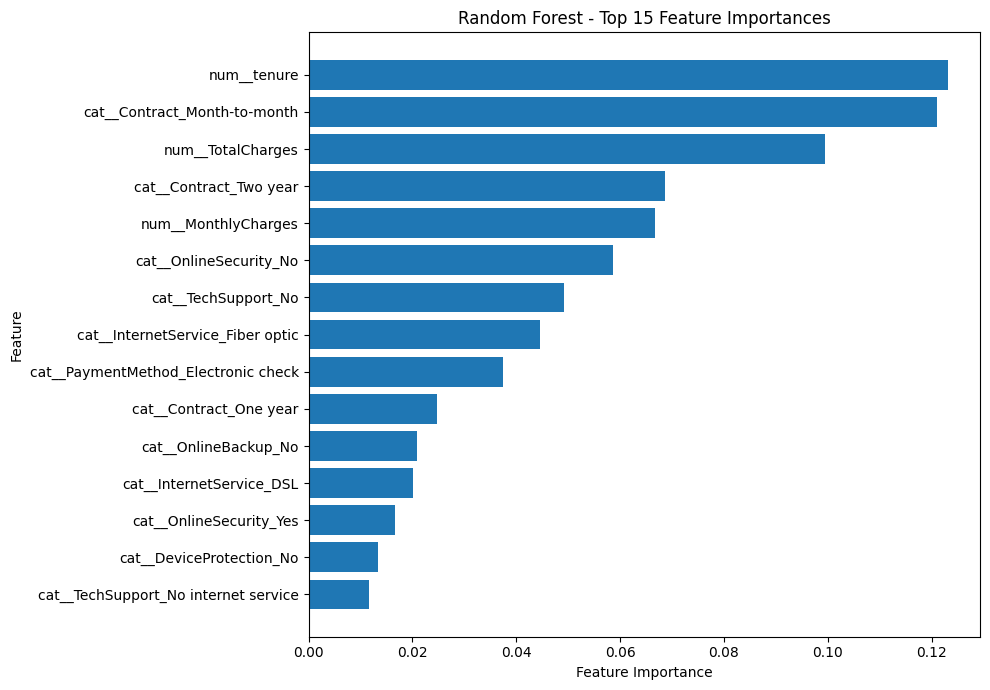

In [43]:
import pandas as pd
import matplotlib.pyplot as plt

# Get feature names after preprocessing
feature_names = preprocessor.get_feature_names_out()

# Extract Random Forest feature importance
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_model.feature_importances_
})

# Sort from highest to lowest
importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

print("TOP 15 FEATURES")
print(importance_df.head(15).round(4).to_string(index=False))

# Plot top 15 features
top_features = importance_df.head(15).sort_values(
    by="Importance"
)

plt.figure(figsize=(10, 7))
plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Random Forest - Top 15 Feature Importances")
plt.tight_layout()
plt.show()

TOP 15 PERMUTATION IMPORTANCES
                         Feature  Importance Mean  Importance Std
               num__TotalCharges           0.0277          0.0054
    cat__Contract_Month-to-month           0.0273          0.0064
                     num__tenure           0.0259          0.0018
cat__InternetService_Fiber optic           0.0070          0.0068
          cat__Contract_One year           0.0044          0.0056
            cat__SeniorCitizen_1           0.0031          0.0010
        cat__PaperlessBilling_No           0.0026          0.0022
          cat__MultipleLines_Yes           0.0024          0.0020
           cat__OnlineBackup_Yes           0.0023          0.0012
            cat__SeniorCitizen_0           0.0020          0.0016
             cat__TechSupport_No           0.0020          0.0012
        cat__StreamingMovies_Yes           0.0019          0.0017
       cat__DeviceProtection_Yes           0.0016          0.0009
       cat__PaperlessBilling_Yes           0.

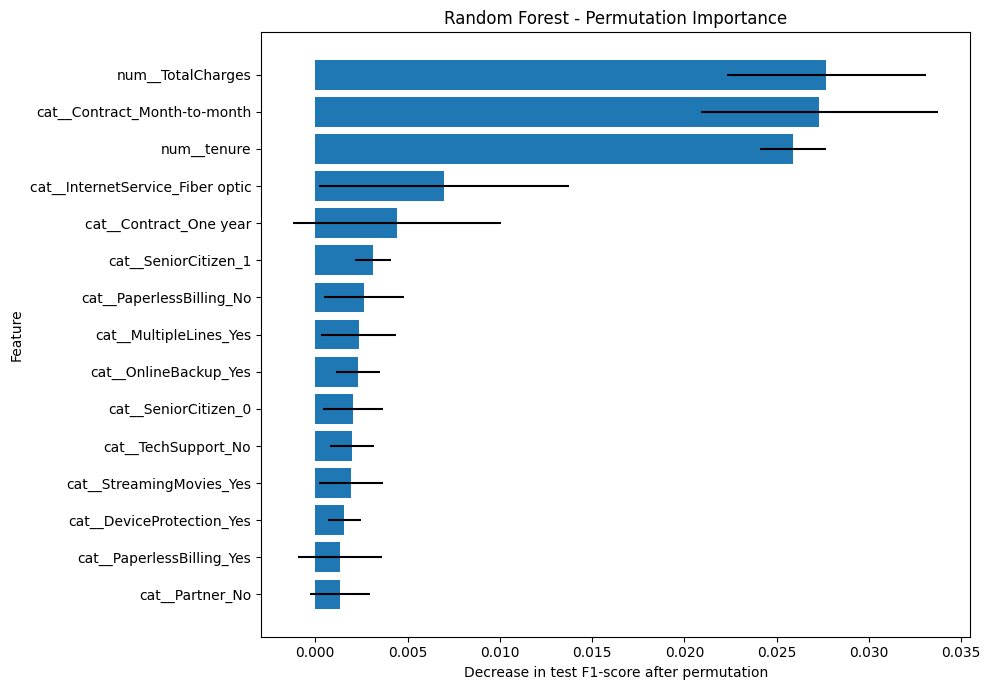

In [44]:
from sklearn.inspection import permutation_importance
import pandas as pd
import matplotlib.pyplot as plt

# Evaluate permutation importance on the held-out test set
permutation_result = permutation_importance(
    rf_model,
    X_test_processed,
    y_test,
    scoring="f1",
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

permutation_df = pd.DataFrame({
    "Feature": preprocessor.get_feature_names_out(),
    "Importance Mean": permutation_result.importances_mean,
    "Importance Std": permutation_result.importances_std
}).sort_values(
    by="Importance Mean",
    ascending=False
)

print("TOP 15 PERMUTATION IMPORTANCES")
print(permutation_df.head(15).round(4).to_string(index=False))

# Plot the top 15 features
top_perm = permutation_df.head(15).sort_values(
    by="Importance Mean"
)

plt.figure(figsize=(10, 7))
plt.barh(
    top_perm["Feature"],
    top_perm["Importance Mean"],
    xerr=top_perm["Importance Std"]
)
plt.xlabel("Decrease in test F1-score after permutation")
plt.ylabel("Feature")
plt.title("Random Forest - Permutation Importance")
plt.tight_layout()
plt.show()

In [45]:
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

models = {
    "Original Logistic Regression": (
        logistic_model, y_pred
    ),
    "Balanced Logistic Regression": (
        balanced_model, y_pred_balanced
    ),
    "Balanced Decision Tree": (
        tree_model, y_pred_tree
    ),
    "Balanced Random Forest": (
        rf_model, y_pred_rf
    )
}

comparison = []

for name, (model, predictions) in models.items():
    probabilities = model.predict_proba(X_test_processed)[:, 1]

    comparison.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Churn Precision": precision_score(y_test, predictions),
        "Churn Recall": recall_score(y_test, predictions),
        "Churn F1": f1_score(y_test, predictions),
        "ROC-AUC": roc_auc_score(y_test, probabilities)
    })

comparison_df = pd.DataFrame(comparison)

print(comparison_df.round(4).to_string(index=False))

                       Model  Accuracy  Churn Precision  Churn Recall  Churn F1  ROC-AUC
Original Logistic Regression    0.8055           0.6572        0.5588    0.6040   0.8420
Balanced Logistic Regression    0.7381           0.5043        0.7834    0.6136   0.8415
      Balanced Decision Tree    0.7544           0.5260        0.7567    0.6206   0.8318
      Balanced Random Forest    0.7637           0.5392        0.7540    0.6288   0.8419


In [46]:
import pandas as pd
from sklearn.metrics import confusion_matrix

models_predictions = {
    "Original Logistic Regression": y_pred,
    "Balanced Logistic Regression": y_pred_balanced,
    "Balanced Decision Tree": y_pred_tree,
    "Balanced Random Forest": y_pred_rf
}

error_comparison = []

for name, predictions in models_predictions.items():
    tn, fp, fn, tp = confusion_matrix(
        y_test, predictions, labels=[0, 1]
    ).ravel()

    error_comparison.append({
        "Model": name,
        "Correctly Identified Churners": tp,
        "Missed Churners": fn,
        "False Churn Alerts": fp,
        "Correctly Identified Stay": tn
    })

error_df = pd.DataFrame(error_comparison)

print(error_df.to_string(index=False))

                       Model  Correctly Identified Churners  Missed Churners  False Churn Alerts  Correctly Identified Stay
Original Logistic Regression                            209              165                 109                        926
Balanced Logistic Regression                            293               81                 288                        747
      Balanced Decision Tree                            283               91                 255                        780
      Balanced Random Forest                            282               92                 241                        794


In [47]:
import pandas as pd
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

# Get predicted probabilities for churn
rf_probabilities = rf_model.predict_proba(
    X_test_processed
)[:, 1]

threshold_results = []

for threshold in [0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60, 0.65, 0.70]:
    predictions = (
        rf_probabilities >= threshold
    ).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Churn Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Churn Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "Churn F1": f1_score(
            y_test, predictions, zero_division=0
        ),
        "Customers Flagged": int(predictions.sum())
    })

threshold_df = pd.DataFrame(threshold_results)

print(
    threshold_df.round(4).to_string(index=False)
)

 Threshold  Churn Precision  Churn Recall  Churn F1  Customers Flagged
      0.30           0.4452        0.8904    0.5936                748
      0.35           0.4671        0.8529    0.6036                683
      0.40           0.4936        0.8262    0.6180                626
      0.45           0.5182        0.7995    0.6288                577
      0.50           0.5392        0.7540    0.6288                523
      0.55           0.5601        0.6979    0.6214                466
      0.60           0.5844        0.6390    0.6105                409
      0.65           0.6222        0.5856    0.6033                352
      0.70           0.6667        0.5080    0.5766                285


In [48]:
from sklearn.metrics import confusion_matrix

for threshold in [0.45, 0.50]:
    predictions = (
        rf_probabilities >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test, predictions, labels=[0, 1]
    ).ravel()

    print(f"\nThreshold: {threshold:.2f}")
    print(f"Correctly identified churners: {tp}")
    print(f"Missed churners: {fn}")
    print(f"False churn alerts: {fp}")
    print(f"Correctly identified stayers: {tn}")


Threshold: 0.45
Correctly identified churners: 299
Missed churners: 75
False churn alerts: 278
Correctly identified stayers: 757

Threshold: 0.50
Correctly identified churners: 282
Missed churners: 92
False churn alerts: 241
Correctly identified stayers: 794


In [49]:
from sklearn.model_selection import StratifiedKFold

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("Cross-validation setup complete.")
print("Number of folds:", cv.get_n_splits())
print("Training rows:", len(X_train))
print("Test rows reserved for final evaluation:", len(X_test))

Cross-validation setup complete.
Number of folds: 5
Training rows: 5634
Test rows reserved for final evaluation: 1409


In [50]:
import numpy as np
from sklearn.base import clone
from sklearn.model_selection import cross_val_predict

# Clone the preprocessing and model setup
rf_pipeline = clone(preprocessor)

from sklearn.pipeline import Pipeline

rf_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("model", clone(rf_model))
])

# Generate out-of-fold churn probabilities using training data only
oof_probabilities = cross_val_predict(
    rf_pipeline,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

print("Cross-validated probabilities generated.")
print("Number of predictions:", len(oof_probabilities))
print("Missing probabilities:", np.isnan(oof_probabilities).sum())
print("Minimum probability:", round(oof_probabilities.min(), 4))
print("Maximum probability:", round(oof_probabilities.max(), 4))

Cross-validated probabilities generated.
Number of predictions: 5634
Missing probabilities: 0
Minimum probability: 0.0018
Maximum probability: 0.9584


In [51]:
import pandas as pd
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

threshold_results_cv = []

for threshold in [
    0.30, 0.35, 0.40, 0.45, 0.50,
    0.55, 0.60, 0.65, 0.70
]:
    predictions = (
        oof_probabilities >= threshold
    ).astype(int)

    threshold_results_cv.append({
        "Threshold": threshold,
        "Churn Precision": precision_score(
            y_train, predictions, zero_division=0
        ),
        "Churn Recall": recall_score(
            y_train, predictions, zero_division=0
        ),
        "Churn F1": f1_score(
            y_train, predictions, zero_division=0
        ),
        "Customers Flagged": int(predictions.sum())
    })

threshold_cv_df = pd.DataFrame(threshold_results_cv)

print(
    threshold_cv_df.round(4).to_string(index=False)
)

 Threshold  Churn Precision  Churn Recall  Churn F1  Customers Flagged
      0.30           0.4499        0.8930    0.5984               2967
      0.35           0.4761        0.8669    0.6147               2722
      0.40           0.4998        0.8388    0.6264               2509
      0.45           0.5260        0.7926    0.6323               2253
      0.50           0.5491        0.7478    0.6332               2036
      0.55           0.5797        0.7003    0.6344               1806
      0.60           0.6119        0.6348    0.6231               1551
      0.65           0.6459        0.5699    0.6055               1319
      0.70           0.6737        0.4943    0.5702               1097


In [52]:
selected_threshold = 0.55

selected_row = threshold_cv_df.loc[
    threshold_cv_df["Threshold"] == selected_threshold
].iloc[0]

print("Provisional threshold:", selected_threshold)
print("Cross-validated churn precision:",
      round(selected_row["Churn Precision"], 4))
print("Cross-validated churn recall:",
      round(selected_row["Churn Recall"], 4))
print("Cross-validated churn F1-score:",
      round(selected_row["Churn F1"], 4))
print("Training customers flagged across OOF predictions:",
      int(selected_row["Customers Flagged"]))

Provisional threshold: 0.55
Cross-validated churn precision: 0.5797
Cross-validated churn recall: 0.7003
Cross-validated churn F1-score: 0.6344
Training customers flagged across OOF predictions: 1806


In [53]:
from sklearn.base import clone
from sklearn.pipeline import Pipeline

final_rf_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("model", clone(rf_model))
])

# Fit using training data only
final_rf_pipeline.fit(X_train, y_train)

print("Final Random Forest pipeline trained.")
print("Training rows:", len(X_train))
print("Test rows reserved for final evaluation:", len(X_test))
print("Selected threshold:", selected_threshold)

Final Random Forest pipeline trained.
Training rows: 5634
Test rows reserved for final evaluation: 1409
Selected threshold: 0.55


In [54]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    f1_score,
    precision_score,
    recall_score
)

# Predict churn probabilities for the test set
y_test_prob = final_rf_pipeline.predict_proba(X_test)[:, 1]

# Apply the selected threshold
y_test_pred = (
    y_test_prob >= selected_threshold
).astype(int)

# Calculate metrics
print("FINAL RANDOM FOREST TEST RESULTS")
print("Threshold:", selected_threshold)
print("Accuracy:", round(accuracy_score(y_test, y_test_pred), 4))
print("Churn Precision:", round(precision_score(y_test, y_test_pred), 4))
print("Churn Recall:", round(recall_score(y_test, y_test_pred), 4))
print("Churn F1-score:", round(f1_score(y_test, y_test_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_test_prob), 4))

print("\nCLASSIFICATION REPORT")
print(classification_report(
    y_test,
    y_test_pred,
    target_names=["Stayed", "Churned"],
    digits=4
))

print("CONFUSION MATRIX")
print(confusion_matrix(y_test, y_test_pred))

FINAL RANDOM FOREST TEST RESULTS
Threshold: 0.55
Accuracy: 0.7743
Churn Precision: 0.5601
Churn Recall: 0.6979
Churn F1-score: 0.6214
ROC-AUC: 0.8419

CLASSIFICATION REPORT
              precision    recall  f1-score   support

      Stayed     0.8802    0.8019    0.8392      1035
     Churned     0.5601    0.6979    0.6214       374

    accuracy                         0.7743      1409
   macro avg     0.7201    0.7499    0.7303      1409
weighted avg     0.7952    0.7743    0.7814      1409

CONFUSION MATRIX
[[830 205]
 [113 261]]


In [56]:
from IPython.display import display as show_table

show_table(final_results.round(4))

,Metric,Value
0,Decision Threshold,0.5500
1,Accuracy,0.7743
2,Churn Precision,0.5601
3,Churn Recall,0.6979
4,Churn F1-Score,0.6214
5,ROC-AUC,0.8419
6,True Positives,261.0000
7,False Positives,205.0000
8,True Negatives,830.0000
9,False Negatives,113.0000


In [58]:
from IPython.display import display as show_table

print("TOP 15 CHURN PREDICTION FEATURES")
show_table(importance_df.head(15).round(4))

TOP 15 CHURN PREDICTION FEATURES


,Feature,Importance
0,num__tenure,0.1232
1,cat__Contract_Month-to-month,0.1211
2,num__TotalCharges,0.0994
3,cat__Contract_Two year,0.0687
4,num__MonthlyCharges,0.0667
5,cat__OnlineSecurity_No,0.0587
6,cat__TechSupport_No,0.0492
7,cat__InternetService_Fiber optic,0.0445
8,cat__PaymentMethod_Electronic check,0.0374
9,cat__Contract_One year,0.0247


In [59]:
# Step 39: Predict churn risk for every customer

# Get churn probabilities for all customers
all_customer_probabilities = final_rf_pipeline.predict_proba(X)[:, 1]

# Create a customer-level risk dataframe
churn_risk_df = pd.DataFrame({
    "CustomerID": df["customerID"].values,
    "ActualChurn": df["Churn"].values,
    "ChurnProbability": all_customer_probabilities
})

# Apply our selected threshold
churn_risk_df["PredictedChurn"] = (
    churn_risk_df["ChurnProbability"] >= selected_threshold
).astype(int)

# Assign risk categories
churn_risk_df["RiskCategory"] = pd.cut(
    churn_risk_df["ChurnProbability"],
    bins=[-0.001, 0.30, 0.55, 1.0],
    labels=["Low Risk", "Medium Risk", "High Risk"]
)

# Sort customers from highest to lowest predicted risk
churn_risk_df = churn_risk_df.sort_values(
    by="ChurnProbability",
    ascending=False
).reset_index(drop=True)

print("CUSTOMER CHURN RISK ANALYSIS")
print("Total customers:", len(churn_risk_df))
print("\nRisk category counts:")
show_table(churn_risk_df["RiskCategory"].value_counts().to_frame("Customers"))

print("\nTop 10 highest-risk customers:")
show_table(churn_risk_df.head(10).round(4))

CUSTOMER CHURN RISK ANALYSIS
Total customers: 7043

Risk category counts:


,Customers
RiskCategory,
Low Risk,3316
High Risk,2289
Medium Risk,1438



Top 10 highest-risk customers:


,CustomerID,ActualChurn,ChurnProbability,PredictedChurn,RiskCategory
0,9497-QCMMS,Yes,0.9481,1,High Risk
1,9300-AGZNL,Yes,0.9478,1,High Risk
2,8149-RSOUN,Yes,0.9440,1,High Risk
3,4910-GMJOT,Yes,0.9429,1,High Risk
4,0295-PPHDO,Yes,0.9416,1,High Risk
5,1069-XAIEM,Yes,0.9410,1,High Risk
6,7024-OHCCK,Yes,0.9380,1,High Risk
7,9282-IZGQK,Yes,0.9364,1,High Risk
8,8603-IJWDN,Yes,0.9361,1,High Risk
9,5419-JPRRN,Yes,0.9357,1,High Risk


In [60]:
# Step 40: Business summary of customer churn risk

risk_summary = (
    churn_risk_df
    .groupby("RiskCategory", observed=False)
    .agg(
        TotalCustomers=("CustomerID", "count"),
        AverageChurnProbability=("ChurnProbability", "mean"),
        ActualChurned=("ActualChurn", lambda s: (s == "Yes").sum()),
        ActualStayed=("ActualChurn", lambda s: (s == "No").sum())
    )
    .reset_index()
)

risk_summary["CustomerPercentage"] = (
    risk_summary["TotalCustomers"] / len(churn_risk_df) * 100
).round(2)

risk_summary["ActualChurnRate"] = (
    risk_summary["ActualChurned"] / risk_summary["TotalCustomers"] * 100
).round(2)

print("CUSTOMER CHURN RISK — BUSINESS SUMMARY")
show_table(risk_summary.round(3))

CUSTOMER CHURN RISK — BUSINESS SUMMARY


,RiskCategory,TotalCustomers,AverageChurnProbability,ActualChurned,ActualStayed,CustomerPercentage,ActualChurnRate
0,Low Risk,3316,0.112,71,3245,47.08,2.14
1,Medium Risk,1438,0.426,334,1104,20.42,23.23
2,High Risk,2289,0.745,1464,825,32.50,63.96


In [61]:
# Create business recommendations for each risk category

retention_strategy = pd.DataFrame({
    "RiskCategory": [
        "High Risk",
        "Medium Risk",
        "Low Risk"
    ],
    "ChurnRate": [
        "63.96%",
        "23.23%",
        "2.14%"
    ],
    "RecommendedAction": [
        "Prioritize personalized retention outreach and investigate service or pricing concerns.",
        "Offer targeted support, explain plan benefits, and encourage suitable longer-term contracts.",
        "Focus on customer satisfaction, service quality, and low-cost loyalty initiatives."
    ],
    "Priority": [
        "High",
        "Medium",
        "Low"
    ]
})

show_table(retention_strategy)

,RiskCategory,ChurnRate,RecommendedAction,Priority
0,High Risk,63.96%,Prioritize personalized retention outreach and...,High
1,Medium Risk,23.23%,"Offer targeted support, explain plan benefits,...",Medium
2,Low Risk,2.14%,"Focus on customer satisfaction, service qualit...",Low


In [62]:
# Step 42: Export project results to CSV

churn_risk_df.to_csv(
    "customer_churn_risk_predictions.csv",
    index=False
)

final_results.to_csv(
    "model_evaluation_results.csv",
    index=False
)

risk_summary.to_csv(
    "customer_risk_summary.csv",
    index=False
)

retention_strategy.to_csv(
    "retention_strategy.csv",
    index=False
)

print("Project files exported successfully:")
print("1. customer_churn_risk_predictions.csv")
print("2. model_evaluation_results.csv")
print("3. customer_risk_summary.csv")
print("4. retention_strategy.csv")

Project files exported successfully:
1. customer_churn_risk_predictions.csv
2. model_evaluation_results.csv
3. customer_risk_summary.csv
4. retention_strategy.csv


In [63]:
# Step 43: Package project outputs into one ZIP file

import zipfile
import os
from google.colab import files

output_files = [
    "customer_churn_risk_predictions.csv",
    "model_evaluation_results.csv",
    "customer_risk_summary.csv",
    "retention_strategy.csv"
]

with zipfile.ZipFile(
    "customer_churn_project_outputs.zip",
    "w",
    zipfile.ZIP_DEFLATED
) as zip_file:
    for filename in output_files:
        if os.path.exists(filename):
            zip_file.write(filename)
        else:
            print("File not found:", filename)

print("Project outputs packaged into ZIP.")
files.download("customer_churn_project_outputs.zip")

Project outputs packaged into ZIP.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [64]:
# Step 44: Save the final trained model

import joblib
from google.colab import files
import os

model_filename = "customer_churn_random_forest.pkl"

joblib.dump(final_rf_pipeline, model_filename)

print("Model saved successfully:", model_filename)
print("File size:", round(os.path.getsize(model_filename) / 1024, 2), "KB")

# Download the saved model
files.download(model_filename)

Model saved successfully: customer_churn_random_forest.pkl
File size: 7637.53 KB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [65]:
# Step 45: Reload and validate the saved model

import joblib
import numpy as np

loaded_model = joblib.load("customer_churn_random_forest.pkl")

# Predict using the reloaded model
reloaded_probabilities = loaded_model.predict_proba(X_test)[:, 1]

# Compare with predictions from the original pipeline
original_probabilities = final_rf_pipeline.predict_proba(X_test)[:, 1]

print("Saved model loaded successfully.")
print("Test customers checked:", len(X_test))
print(
    "Predictions match:",
    np.allclose(original_probabilities, reloaded_probabilities)
)
print(
    "Maximum prediction difference:",
    round(
        float(np.max(np.abs(
            original_probabilities - reloaded_probabilities
        ))),
        10
    )
)

Saved model loaded successfully.
Test customers checked: 1409
Predictions match: True
Maximum prediction difference: 0.0


In [66]:
# Step 46: Reusable customer churn prediction function

def predict_customer_churn(customer_data):
    """
    Predict churn risk for one customer.

    customer_data must contain the same 19 input features
    used during model training.
    """

    customer_df = pd.DataFrame([customer_data])

    # Ensure the input contains the expected features in the correct order
    customer_df = customer_df[X.columns]

    # Predict churn probability
    probability = loaded_model.predict_proba(customer_df)[0, 1]

    # Assign risk category
    if probability < 0.30:
        risk = "Low Risk"
        action = "Maintain service quality and customer satisfaction."
    elif probability < selected_threshold:
        risk = "Medium Risk"
        action = "Consider targeted support and plan review."
    else:
        risk = "High Risk"
        action = "Prioritize personalized retention outreach."

    return {
        "ChurnProbability": round(float(probability), 4),
        "RiskCategory": risk,
        "RecommendedAction": action
    }


print("Customer churn prediction function created successfully.")

Customer churn prediction function created successfully.


In [67]:
# Step 47: Test using one customer from the dataset

# Select one customer from the original dataset
customer_index = 0

sample_customer = X.iloc[customer_index].to_dict()

# Get the prediction
prediction = predict_customer_churn(sample_customer)

print("CUSTOMER CHURN PREDICTION")
print("-------------------------")
print("Customer ID:", df.iloc[customer_index]["customerID"])
print("Actual Churn:", df.iloc[customer_index]["Churn"])
print("Predicted Churn Probability:",
      prediction["ChurnProbability"])
print("Risk Category:", prediction["RiskCategory"])
print("Recommended Action:", prediction["RecommendedAction"])

CUSTOMER CHURN PREDICTION
-------------------------
Customer ID: 7590-VHVEG
Actual Churn: No
Predicted Churn Probability: 0.6931
Risk Category: High Risk
Recommended Action: Prioritize personalized retention outreach.


In [68]:
# Step 48: Test predictions on 5 customers

sample_indices = [0, 10, 50, 100, 200]

sample_results = []

for idx in sample_indices:
    customer_data = X.iloc[idx].to_dict()

    result = predict_customer_churn(customer_data)

    sample_results.append({
        "CustomerID": df.iloc[idx]["customerID"],
        "ActualChurn": df.iloc[idx]["Churn"],
        "ChurnProbability": result["ChurnProbability"],
        "RiskCategory": result["RiskCategory"],
        "PredictedChurn": (
            "Yes"
            if result["ChurnProbability"] >= selected_threshold
            else "No"
        )
    })

sample_results_df = pd.DataFrame(sample_results)

print("FIVE-CUSTOMER PREDICTION TEST")
show_table(sample_results_df)

FIVE-CUSTOMER PREDICTION TEST


,CustomerID,ActualChurn,ChurnProbability,RiskCategory,PredictedChurn
0,7590-VHVEG,No,0.6931,High Risk,Yes
1,9763-GRSKD,No,0.2735,Low Risk,No
2,8012-SOUDQ,No,0.7153,High Risk,Yes
3,6380-ARCEH,No,0.5636,High Risk,Yes
4,9323-HGFWY,No,0.4485,Medium Risk,No


In [69]:
# Step 49: Final Customer Churn Project Summary

project_summary = pd.DataFrame({
    "Category": [
        "Dataset",
        "Total Customers",
        "Historical Churn Rate",
        "Selected Model",
        "Decision Threshold",
        "Test Accuracy",
        "Churn Precision",
        "Churn Recall",
        "Churn F1-Score",
        "ROC-AUC",
        "High-Risk Customers",
        "Medium-Risk Customers",
        "Low-Risk Customers",
        "Top Predictive Feature"
    ],
    "Result": [
        "IBM Telco Customer Churn",
        len(df),
        f"{(df['Churn'] == 'Yes').mean() * 100:.2f}%",
        "Balanced Random Forest",
        selected_threshold,
        round(accuracy_score(y_test, y_test_pred), 4),
        round(precision_score(y_test, y_test_pred), 4),
        round(recall_score(y_test, y_test_pred), 4),
        round(f1_score(y_test, y_test_pred), 4),
        round(roc_auc_score(y_test, y_test_prob), 4),
        int((churn_risk_df["RiskCategory"] == "High Risk").sum()),
        int((churn_risk_df["RiskCategory"] == "Medium Risk").sum()),
        int((churn_risk_df["RiskCategory"] == "Low Risk").sum()),
        importance_df.iloc[0]["Feature"]
    ]
})

show_table(project_summary)

,Category,Result
0,Dataset,IBM Telco Customer Churn
1,Total Customers,7043
2,Historical Churn Rate,26.54%
3,Selected Model,Balanced Random Forest
4,Decision Threshold,0.55
5,Test Accuracy,0.7743
6,Churn Precision,0.5601
7,Churn Recall,0.6979
8,Churn F1-Score,0.6214
9,ROC-AUC,0.8419


In [70]:
# Step 50: Export the final project summary

project_summary.to_csv(
    "customer_churn_project_summary.csv",
    index=False
)

print("Project summary exported successfully.")
print("File: customer_churn_project_summary.csv")

Project summary exported successfully.
File: customer_churn_project_summary.csv


In [71]:
%%writefile README.md

# Customer Churn & Retention Analysis

## Project Overview
This project analyzes telecom customer data to identify churn patterns,
predict customers at risk of leaving, and recommend targeted retention
strategies using machine learning.

## Dataset
- Dataset: IBM Telco Customer Churn
- Total customers: 7,043
- Historical churn rate: 26.54%

## Tools & Technologies
- Python
- Pandas and NumPy
- Scikit-learn
- Matplotlib and Seaborn (for exploratory analysis)
- Google Colab

## Project Workflow
1. Data cleaning and preprocessing
2. Exploratory data analysis
3. Feature engineering
4. Train-test split and preprocessing
5. Machine learning model comparison
6. Threshold selection using cross-validation
7. Final model evaluation
8. Customer risk segmentation
9. Retention strategy recommendations

## Final Model
- Model: Balanced Random Forest
- Decision threshold: 0.55
- Accuracy: 77.43%
- Churn precision: 56.01%
- Churn recall: 69.79%
- Churn F1-score: 62.14%
- ROC-AUC: 0.8419

## Key Predictive Features
- Customer tenure
- Contract type
- Total charges
- Monthly charges
- Online security
- Technical support
- Internet service
- Payment method

## Business Recommendations
- Prioritize personalized retention outreach for high-risk customers.
- Provide targeted support to medium-risk customers.
- Maintain customer satisfaction with low-cost loyalty initiatives for low-risk customers.

## Project Outputs
- Customer churn risk predictions
- Model evaluation results
- Customer risk summary
- Retention strategy table
- Final project summary
- Saved machine learning pipeline

## Important Limitation
The model identifies statistical patterns associated with churn.
Feature importance does not establish causation, and predicted risk
does not guarantee that a customer will leave.

The test set was examined during earlier exploratory model comparisons
and threshold analyses. Final test metrics should therefore be interpreted
with that limitation in mind.

Writing README.md


In [72]:
# Step 52: Verify README.md

import os

readme_path = "README.md"

if os.path.exists(readme_path):
    print("README.md exists.")
    print("\nFile size:", os.path.getsize(readme_path), "bytes")

    with open(readme_path, "r", encoding="utf-8") as file:
        print("\nREADME PREVIEW\n")
        print(file.read())
else:
    print("README.md was not found.")

README.md exists.

File size: 1972 bytes

README PREVIEW


# Customer Churn & Retention Analysis

## Project Overview
This project analyzes telecom customer data to identify churn patterns,
predict customers at risk of leaving, and recommend targeted retention
strategies using machine learning.

## Dataset
- Dataset: IBM Telco Customer Churn
- Total customers: 7,043
- Historical churn rate: 26.54%

## Tools & Technologies
- Python
- Pandas and NumPy
- Scikit-learn
- Matplotlib and Seaborn (for exploratory analysis)
- Google Colab

## Project Workflow
1. Data cleaning and preprocessing
2. Exploratory data analysis
3. Feature engineering
4. Train-test split and preprocessing
5. Machine learning model comparison
6. Threshold selection using cross-validation
7. Final model evaluation
8. Customer risk segmentation
9. Retention strategy recommendations

## Final Model
- Model: Balanced Random Forest
- Decision threshold: 0.55
- Accuracy: 77.43%
- Churn precision: 56.01%
- Churn recall: 69.79

In [73]:
import os

required_files = [
    "README.md",
    "customer_churn_risk_predictions.csv",
    "model_evaluation_results.csv",
    "customer_risk_summary.csv",
    "retention_strategy.csv",
    "customer_churn_project_summary.csv",
    "customer_churn_random_forest.pkl",
    "customer_churn_project_outputs.zip"
]

print("PROJECT FILE VERIFICATION")
print("=" * 55)

for filename in required_files:
    if os.path.exists(filename):
        size_kb = os.path.getsize(filename) / 1024
        print(f"[FOUND]   {filename} ({size_kb:.2f} KB)")
    else:
        print(f"[MISSING] {filename}")

print("=" * 55)

PROJECT FILE VERIFICATION
[FOUND]   README.md (1.93 KB)
[FOUND]   customer_churn_risk_predictions.csv (314.40 KB)
[FOUND]   model_evaluation_results.csv (0.27 KB)
[FOUND]   customer_risk_summary.csv (0.27 KB)
[FOUND]   retention_strategy.csv (0.38 KB)
[FOUND]   customer_churn_project_summary.csv (0.36 KB)
[FOUND]   customer_churn_random_forest.pkl (7637.53 KB)
[FOUND]   customer_churn_project_outputs.zip (121.62 KB)


In [74]:
import zipfile
import os

zip_path = "customer_churn_project_outputs.zip"

expected_files = [
    "customer_churn_risk_predictions.csv",
    "model_evaluation_results.csv",
    "customer_risk_summary.csv",
    "retention_strategy.csv"
]

print("ZIP PACKAGE VERIFICATION")
print("=" * 55)

with zipfile.ZipFile(zip_path, "r") as zip_file:
    zip_contents = zip_file.namelist()

    for filename in expected_files:
        if filename in zip_contents:
            print(f"[FOUND]   {filename}")
        else:
            print(f"[MISSING] {filename}")

    print("\nZIP integrity check:", end=" ")
    print("Passed" if zip_file.testzip() is None else "Failed")

print("\nZIP size:", round(os.path.getsize(zip_path) / 1024, 2), "KB")

ZIP PACKAGE VERIFICATION
[FOUND]   customer_churn_risk_predictions.csv
[FOUND]   model_evaluation_results.csv
[FOUND]   customer_risk_summary.csv
[FOUND]   retention_strategy.csv

ZIP integrity check: Passed

ZIP size: 121.62 KB


In [75]:
import os

project_structure = {
    "customer-churn-retention-analysis": [
        "data",
        "outputs",
        "models",
        "docs"
    ]
}

for project_folder, subfolders in project_structure.items():
    os.makedirs(project_folder, exist_ok=True)

    for subfolder in subfolders:
        os.makedirs(
            os.path.join(project_folder, subfolder),
            exist_ok=True
        )

print("Project folder structure created successfully.\n")

for root, dirs, files in os.walk("customer-churn-retention-analysis"):
    level = root.count(os.sep)
    indent = "    " * level
    print(f"{indent}{os.path.basename(root)}/")

Project folder structure created successfully.

customer-churn-retention-analysis/
    models/
    docs/
    outputs/
    data/


In [76]:
import os
import shutil

project_dir = "customer-churn-retention-analysis"

# Documentation
shutil.copy2(
    "README.md",
    os.path.join(project_dir, "README.md")
)

# Model
shutil.copy2(
    "customer_churn_random_forest.pkl",
    os.path.join(project_dir, "models", "customer_churn_random_forest.pkl")
)

# Project outputs
output_files = [
    "customer_churn_risk_predictions.csv",
    "model_evaluation_results.csv",
    "customer_risk_summary.csv",
    "retention_strategy.csv",
    "customer_churn_project_summary.csv",
    "customer_churn_project_outputs.zip"
]

for filename in output_files:
    shutil.copy2(
        filename,
        os.path.join(project_dir, "outputs", filename)
    )

print("Project files copied successfully!\n")

for root, dirs, files in os.walk(project_dir):
    level = root.replace(project_dir, "").count(os.sep)
    indent = "    " * level
    print(f"{indent}{os.path.basename(root)}/")

    for filename in sorted(files):
        print(f"{indent}    {filename}")

Project files copied successfully!

customer-churn-retention-analysis/
    README.md
    models/
        customer_churn_random_forest.pkl
    docs/
    outputs/
        customer_churn_project_outputs.zip
        customer_churn_project_summary.csv
        customer_churn_risk_predictions.csv
        customer_risk_summary.csv
        model_evaluation_results.csv
        retention_strategy.csv
    data/


In [77]:

import os

project_dir = "customer-churn-retention-analysis"

gitignore_content = """# Raw or private data
data/*
!data/.gitkeep

# Trained model files
models/*.pkl
models/*.joblib

# Customer-level predictions and ZIP containing them
outputs/customer_churn_risk_predictions.csv
outputs/customer_churn_project_outputs.zip

# Notebook checkpoints and Python cache
.ipynb_checkpoints/
__pycache__/
*.pyc

# Environment files
.env
"""

gitignore_path = os.path.join(project_dir, ".gitignore")

with open(gitignore_path, "w", encoding="utf-8") as file:
    file.write(gitignore_content)

# Keep the empty data folder visible in Git
with open(os.path.join(project_dir, "data", ".gitkeep"), "w") as file:
    file.write("")

print(".gitignore created successfully.\n")
print("Rules added:")
print(gitignore_content)


.gitignore created successfully.

Rules added:
# Raw or private data
data/*
!data/.gitkeep

# Trained model files
models/*.pkl
models/*.joblib

# Customer-level predictions and ZIP containing them
outputs/customer_churn_risk_predictions.csv
outputs/customer_churn_project_outputs.zip

# Notebook checkpoints and Python cache
.ipynb_checkpoints/
__pycache__/
*.pyc

# Environment files
.env



In [78]:

import os

project_dir = "customer-churn-retention-analysis"

print("GITHUB PROJECT REVIEW")
print("=" * 55)

for root, dirs, files in os.walk(project_dir):
    dirs.sort()
    level = root.replace(project_dir, "").count(os.sep)
    indent = "    " * level
    print(f"{indent}{os.path.basename(root)}/")

    for filename in sorted(files):
        print(f"{indent}    {filename}")

print("\nREQUIRED FILES")
for filename in ["README.md", ".gitignore", "data/.gitkeep"]:
    path = os.path.join(project_dir, filename)
    status = "FOUND" if os.path.isfile(path) else "MISSING"
    print(f"[{status}] {filename}")

print("\nFILES THAT SHOULD BE EXCLUDED FROM GITHUB")
excluded_files = [
    "models/customer_churn_random_forest.pkl",
    "outputs/customer_churn_risk_predictions.csv",
    "outputs/customer_churn_project_outputs.zip"
]

for filename in excluded_files:
    path = os.path.join(project_dir, filename)
    status = "PRESENT LOCALLY" if os.path.isfile(path) else "NOT FOUND"
    print(f"[{status}] {filename}")


GITHUB PROJECT REVIEW
customer-churn-retention-analysis/
    .gitignore
    README.md
    data/
        .gitkeep
    docs/
    models/
        customer_churn_random_forest.pkl
    outputs/
        customer_churn_project_outputs.zip
        customer_churn_project_summary.csv
        customer_churn_risk_predictions.csv
        customer_risk_summary.csv
        model_evaluation_results.csv
        retention_strategy.csv

REQUIRED FILES
[FOUND] README.md
[FOUND] .gitignore
[FOUND] data/.gitkeep

FILES THAT SHOULD BE EXCLUDED FROM GITHUB
[PRESENT LOCALLY] models/customer_churn_random_forest.pkl
[PRESENT LOCALLY] outputs/customer_churn_risk_predictions.csv
[PRESENT LOCALLY] outputs/customer_churn_project_outputs.zip
